# Определение авторства с помощью сжатия

Воспроизведение результатов статьи:
> Ryabko, B.; Savina, N. Using Data Compression to Build a Method for Statistically Verified Attribution of Literary Texts. Entropy 2021, 23, 1302.

## Задачи проекта
- **(a)** Воспроизвести результаты статьи.
- **(b)** Исследовать влияние выбора метода сжатия (включая нейросетевые).
- **(c)** Рассмотреть задачу выбора лучшего перевода для данного автора.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.theory import phi, phi_authors, build_table, chi_square, significance_level, get_accuracy
from src.preprocessing import run_data_pipeline, split_into_slices
from src.data_pipeline import process
from src.neural_method import clear_model_cache

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

## 1. Подготовка данных

### 1.1 Списки авторов

In [2]:
# Авторы 1915-1940 годов (Таблица 1 в статье)
AUTHORS_1915_1940 = [
    'Pasternak', 'Nabokov', 'Paustovsky', 'Veresayev', 'Zamyatin',
    'Bunin', 'Gorky', 'Kuprin', 'Platonov', 'Mandelstam',
    'Olesha', 'Katayev', 'Green', 'Zhitkov', 'Ehrenburg',
    'Tynyanov', 'Gaidar'
]
AUTHORS_1915_1940 = AUTHORS_1915_1940

# Авторы для эксперимента 1: Ильф/Петров и Булгаков (Таблицы 3-5)
AUTHORS_BULGAKOV = ['Bulgakov', 'Ilf_and_Petrov']

# Авторы 19 века (Таблица 6)
AUTHORS_19_CENTURY = [
    'Nekrasov', 'Panaeva', 'Turgenev', 'Goncharov', 'Gogol', 'Dahl',
    'Dostoevsky', 'Panaev', 'SShchedrin', 'Tolstoy'
]

# Типы предобработки
PREPROCESS_TYPES = [
    'lower_nopunct_nostop',
    'lower_nopunct_withstop',
    'origcase_nopunct_nostop',
    'origcase_nopunct_withstop',
    'lower_withpunct_nostop',
    'origcase_withpunct_nostop',
    'lower_withpunct_withstop',
    'origcase_withpunct_withstop'
]

# Компрессоры (классические + нейросетевые)
# ts_zip/nncp/cmix требуют внешних зависимостей — будут пропущены если недоступны
COMPRESSORS = ['gzip', 'bzip2', 'lzma', 'zstd', 'brotli', 'paq', 'llm', 'ts_zip', 'nncp', 'cmix']

### 1.2 Генерация датасетов

In [3]:
TRAIN_KB = 128
TEST_KB = 64
N_SLICES = 16

run_data_pipeline(AUTHORS_1915_1940, train_kb=TRAIN_KB, test_kb=TEST_KB, seed=42)
split_into_slices(AUTHORS_1915_1940, n_slices=N_SLICES)

Генерация датасета
Для Bunin!
Готово! Сохранено в папке data/processed/Bunin/lower_nopunct_nostop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке data/processed/Bunin/lower_nopunct_withstop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке data/processed/Bunin/origcase_nopunct_nostop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке data/processed/Bunin/origcase_nopunct_withstop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке data/processed/Bunin/lower_withpunct_nostop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке da

---
## 2. Эксперимент 1: Таблица 1 (17 авторов 1915-1940)

In [4]:
def run_experiment(authors, preprocess_type, n_slices, compressor, lvl=6):
    table = build_table(authors, preprocess_type, n_slices, compressor, lvl)
    chi2, p_value, df = significance_level(table)
    accuracy = get_accuracy(table)
    return {
        'table': table,
        'chi2': chi2,
        'p_value': p_value,
        'df': df,
        'accuracy': accuracy
    }

In [5]:
result = run_experiment(
    authors=AUTHORS_1915_1940,
    preprocess_type='origcase_withpunct_withstop',
    n_slices=16,
    compressor='lzma',
    lvl=6
)
result['table']

,Pasternak,Nabokov,Paustovsky,Veresayev,Zamyatin,Bunin,Gorky,Kuprin,Platonov,Mandelstam,Olesha,Katayev,Green,Zhitkov,Ehrenburg,Tynyanov,Gaidar
Pasternak,15,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Nabokov,0,14,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0
Paustovsky,0,1,12,0,0,0,0,0,0,1,0,1,0,0,1,0,0
Veresayev,0,0,1,7,0,0,5,0,0,0,0,1,0,1,0,0,1
Zamyatin,0,0,0,0,12,1,0,2,0,0,0,0,0,0,0,0,1
Bunin,0,0,0,0,0,11,1,4,0,0,0,0,0,0,0,0,0
Gorky,0,0,0,1,0,0,15,0,0,0,0,0,0,0,0,0,0
Kuprin,0,0,0,0,0,2,0,10,0,2,0,0,1,0,1,0,0
Platonov,0,0,0,0,0,0,0,0,14,0,0,1,0,0,0,0,1
Mandelstam,1,0,0,0,0,0,0,0,0,15,0,0,0,0,0,0,0


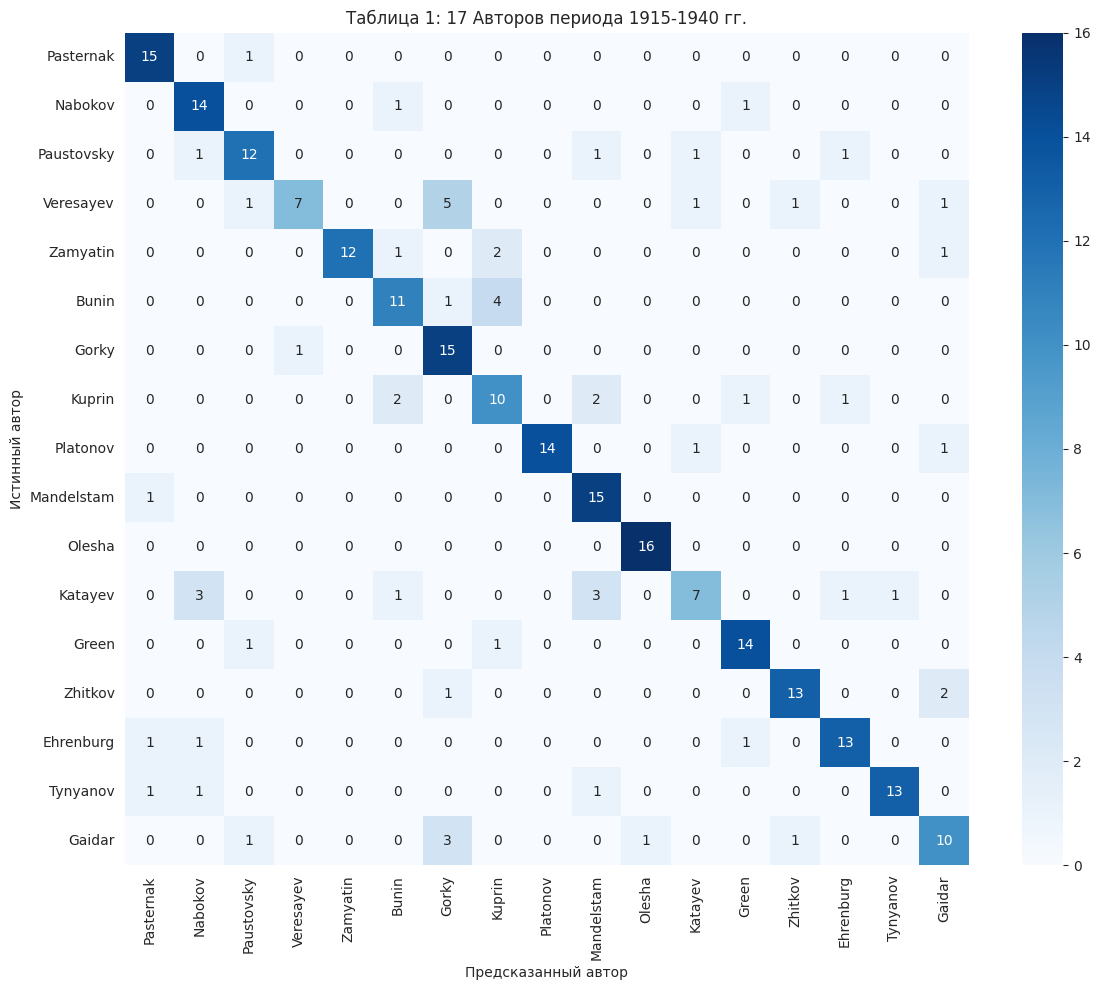

In [6]:
def plot_confusion_matrix(table, title='Confusion Matrix'):
    plt.figure(figsize=(12, 10))
    sns.heatmap(table, annot=True, fmt='d', cmap='Blues')
    plt.title(title)j
    plt.xlabel('Предсказанный автор')
    plt.ylabel('Истинный автор')
    plt.tight_layout()
    plt.show()

plot_confusion_matrix(result['table'], 'Таблица 1: 17 Авторов периода 1915-1940 гг.')

### 2.1 Сравнение типов предобработки (Таблица 2)

In [ ]:
def compare_preprocessing(authors, n_slices, compressor, lvl=6):
    results = []
    for preprocess_type in PREPROCESS_TYPES:
        try:
            res = run_experiment(authors, preprocess_type, n_slices, compressor, lvl)
            results.append({
                'preprocessing': preprocess_type,
                'chi2': res['chi2'],
                'accuracy': res['accuracy'],
                'p_value': res['p_value']
            })
        except FileNotFoundError as e:
            print(f"Skipping {preprocess_type}: {e}")
    return pd.DataFrame(results).sort_values('chi2', ascending=False)

preprocessing_comparison = compare_preprocessing(AUTHORS_1915_1940, 16, 'lzma')
preprocessing_comparison

### 2.2 Сравнение компрессоров

In [ ]:
def compare_compressors(authors, preprocess_type, n_slices):
    results = []
    compressor_levels = {
        'gzip': 6, 'bzip2': 6, 'lzma': 6,
        'zstd': 10, 'brotli': 6, 'paq': 1,
        'llm': 1, 'ts_zip': 1, 'nncp': 1, 'cmix': 1
    }
    for compressor, lvl in compressor_levels.items():
        try:
            print(f"Testing {compressor}...")
            res = run_experiment(authors, preprocess_type, n_slices, compressor, lvl)
            results.append({
                'compressor': compressor,
                'chi2': res['chi2'],
                'accuracy': res['accuracy'],
                'p_value': res['p_value']
            })
            # Освобождаем память после нейросетевых компрессоров
            if compressor in ('paq', 'llm', 'ts_zip'):
                clear_model_cache()
        except Exception as e:
            print(f"Error with {compressor}: {e}")
    return pd.DataFrame(results).sort_values('chi2', ascending=False)

compressor_comparison = compare_compressors(AUTHORS_1915_1940, 'origcase_nopunct_withstop', 16)
compressor_comparison

---
## 3. Эксперимент 2: Булгаков и Ильф/Петров (Таблицы 3-5)

In [ ]:
def attribution_experiment(authors, disputed_slices_dir, preprocess_type, n_slices, compressor, lvl=6):
    authors_paths = {}
    for author in authors:
        train_path = Path('data/processed') / author / preprocess_type / 'Train.txt'
        if train_path.exists():
            authors_paths[author] = train_path
    
    attribution_counts = {author: 0 for author in authors}
    slices_path = Path(disputed_slices_dir)
    phi_T1_cache = {}
    
    for i in range(n_slices):
        slice_path = slices_path / f'{i}_slice.txt'
        if not slice_path.exists():
            continue
        phi_vals = phi_authors(compressor, authors_paths, slice_path, lvl, phi_T1_cache)
        predicted_author = min(phi_vals, key=phi_vals.get)
        attribution_counts[predicted_author] += 1
    
    return attribution_counts

In [ ]:
TRAIN_KB = 256
TEST_KB = 128
N_SLICES = 64

run_data_pipeline(AUTHORS_BULGAKOV, train_kb=TRAIN_KB, test_kb=TEST_KB, seed=42)
split_into_slices(AUTHORS_BULGAKOV, n_slices=N_SLICES)

In [ ]:
# Таблица 4: Кросс-проверка
result_cross = run_experiment(AUTHORS_BULGAKOV, 'origcase_nopunct_withstop', 64, 'lzma')
result_cross['table']

---
## 4. Эксперимент 3: Некрасов/Панаева (Таблицы 6-8)

In [ ]:
TRAIN_KB = 128
TEST_KB = 128
N_SLICES = 16

run_data_pipeline(AUTHORS_19_CENTURY, train_kb=TRAIN_KB, test_kb=TEST_KB, seed=42)
split_into_slices(AUTHORS_19_CENTURY, n_slices=N_SLICES)

In [ ]:
result_19c = run_experiment(AUTHORS_19_CENTURY, 'origcase_nopunct_withstop', 16, 'lzma')
print(f"chi2 = {result_19c['chi2']:.1f}")
result_19c['table']

In [ ]:
def attribute_chapters(authors, chapters_paths, preprocess_type, n_slices, compressor, lvl=6):
    results = []
    for chapter_name, chapter_path in chapters_paths.items():
        counts = attribution_experiment(authors, chapter_path, preprocess_type, n_slices, compressor, lvl)
        row = {'chapter': chapter_name}
        row.update(counts)
        results.append(row)
    return pd.DataFrame(results).set_index('chapter')

---
## 5. Сравнение методов сжатия (Цель b)

In [13]:
def plot_compressor_comparison(results):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    axes[0].bar(results['compressor'], results['chi2'], color='steelblue')
    axes[0].set_xlabel('Compressor')
    axes[0].set_ylabel('chi2')
    axes[0].set_title('chi2 by Compressor')
    axes[0].tick_params(axis='x', rotation=45)
    
    axes[1].bar(results['compressor'], results['accuracy'] * 100, color='forestgreen')
    axes[1].set_xlabel('Compressor')
    axes[1].set_ylabel('Accuracy (%)')
    axes[1].set_title('Accuracy by Compressor')
    axes[1].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()

---
## 6. Задача выбора лучшего перевода (Цель c)

In [14]:
def compare_translations(original_author_path, translations_paths, compressor='lzma', lvl=6):
    results = {}
    original_path = Path(original_author_path)
    
    for translator, translation_path in translations_paths.items():
        phi_val = phi(compressor, original_path, Path(translation_path), lvl)
        results[translator] = phi_val
    
    return dict(sorted(results.items(), key=lambda x: x[1]))

---
## 7. Итоговый отчёт

In [15]:
def summary_report(experiments_results):
    print("=" * 60)
    print("SUMMARY REPORT")
    print("=" * 60)
    
    for name, result in experiments_results.items():
        print(f"\n{name}:")
        print(f"  chi2 = {result['chi2']:.1f}")
        print(f"  p-value = {result['p_value']:.2e}")
        print(f"  Accuracy = {result['accuracy']:.2%}")
        
        if result['p_value'] < 0.000001:
            print(f"  -> H0 rejected at significance level 0.000001")
        elif result['p_value'] < 0.01:
            print(f"  -> H0 rejected at significance level 0.01")